In [ ]:
# ============================================================
# PRÁCTICA 6 - DBSCAN / KMeans / KMeans+RKHS
# Bloque 0: Instalación e importaciones
# ============================================================

!pip install gdown --quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             adjusted_rand_score, homogeneity_score,
                             completeness_score, v_measure_score,
                             normalized_mutual_info_score,
                             adjusted_mutual_info_score)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import rbf_kernel

pd.set_option('display.max_rows', None)

Downloading...
From: https://drive.google.com/uc?id=1jRCHr-Jo2WFhhdJXCpfm_T_dSJjI6OzI
To: /content/dataset_p6.csv
100% 61.0k/61.0k [00:00<00:00, 18.6MB/s]
Primeros elementos del dataset:


,x,y
0,-1.214299,1.412649
1,1.908018,-0.443996
2,-0.123495,-1.970080
3,-1.674425,-1.139345
4,1.162182,1.606780



Análisis estadístico descriptivo:


,x,y
count,1600.000000,1600.000000
mean,-0.015036,6.739025
std,10.889734,7.258496
min,-18.515338,-6.317141
25%,-7.464264,-0.081129
50%,-0.032261,7.507457
75%,7.621938,13.572895
max,18.538913,19.711485


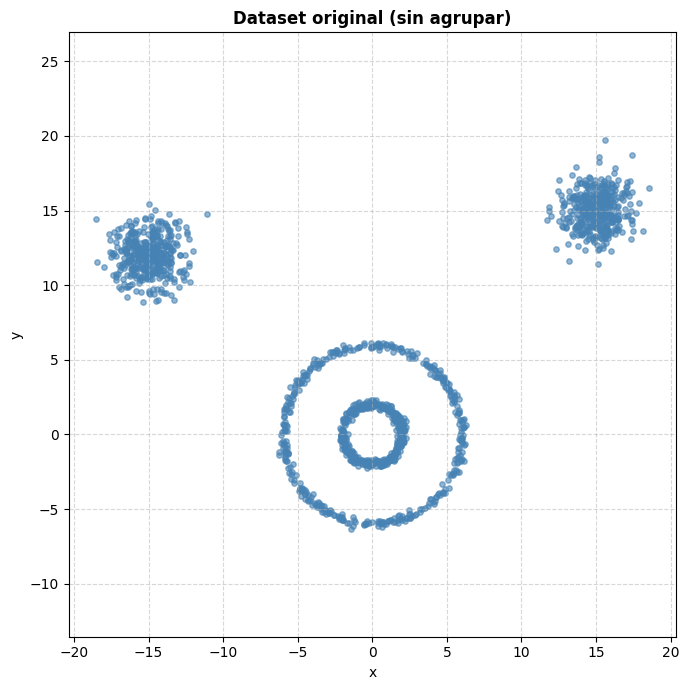

In [ ]:
# ============================================================
# Tarea 1.1: Carga del dataset y análisis inicial
# ============================================================

# Descarga del dataset desde Google Drive
!gdown 1jRCHr-Jo2WFhhdJXCpfm_T_dSJjI6OzI

# Carga en DataFrame
dataset = pd.read_csv('dataset_p6.csv', delimiter=',')

# Primeros elementos
print("Primeros elementos del dataset:")
display(dataset.head())

# Análisis estadístico descriptivo
print("\nAnálisis estadístico descriptivo:")
display(dataset.describe())

# Representación gráfica con un solo color (sin agrupar)
plt.figure(figsize=(7, 7))
plt.scatter(dataset.iloc[:, 0], dataset.iloc[:, 1], s=15, alpha=0.6, color='steelblue')
plt.title("Dataset original (sin agrupar)", fontweight='bold')
plt.xlabel(dataset.columns[0])
plt.ylabel(dataset.columns[1])
plt.axis('equal') #importante para que no se deformen las figuras
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Análisis del dataset y previsión de resultados

El dataset está compuesto por puntos 2D que forman **cuatro formas geométricas diferenciadas**,
combinando estructuras no convexas (por ejemplo, anillos, medias lunas) con estructuras convexas
(por ejemplo, nubes de puntos compactas o elipses). Esta combinación hace que el problema de
clustering sea especialmente desafiante, ya que ningún algoritmo clásico domina en todos los casos.

### Previsión por algoritmo

**DBSCAN:**
Al basarse en densidad local, DBSCAN tiene una ventaja clara frente a los otros dos algoritmos
para detectar formas no convexas. Si los valores de `eps` y `min_samples` se ajustan correctamente,
es el algoritmo con más posibilidades de separar las cuatro formas geométricas. Sin embargo,
cuando las densidades entre formas son muy distintas, un único valor de `eps` puede ser insuficiente
para capturar todas las estructuras simultáneamente. También generará puntos de ruido que no
pertenecerán a ningún grupo.

**KMeans:**
KMeans asume que los grupos son convexos y de densidad similar, por lo que fallará en las formas
no convexas. Dividirá los anillos o medias lunas en partes, mezclando puntos de distintas formas.
Para las estructuras convexas sí obtendrá buenos resultados. En general, se espera una agrupación
visualmente incorrecta para al menos dos de las cuatro formas geométricas.

**KMeans-RKHS:**
Al proyectar los datos al espacio de características asociado al kernel RBF, KMeans-RKHS puede
capturar geometrías no convexas que KMeans estándar no puede. Con un valor adecuado de `gamma`,
es posible que este algoritmo también detecte correctamente las cuatro formas. Valores de `gamma`
demasiado pequeños se comportarán como KMeans estándar; valores demasiado grandes pueden
sobreajustar y fragmentar los grupos.

### Sobre los índices internos de validación

Los índices **Silhouette** y **Calinski-Harabasz** están diseñados para medir la compacidad y
separación de grupos en el espacio original. Ambos favorecen grupos convexos y compactos, por lo
que **no reflejarán bien la calidad visual del agrupamiento** cuando las formas son no convexas.
Es posible que KMeans obtenga mejores índices que DBSCAN aunque su resultado visual sea peor,
precisamente porque KMeans genera grupos más compactos y separados en el espacio euclídeo,
aunque no correspondan a las formas reales del dataset.

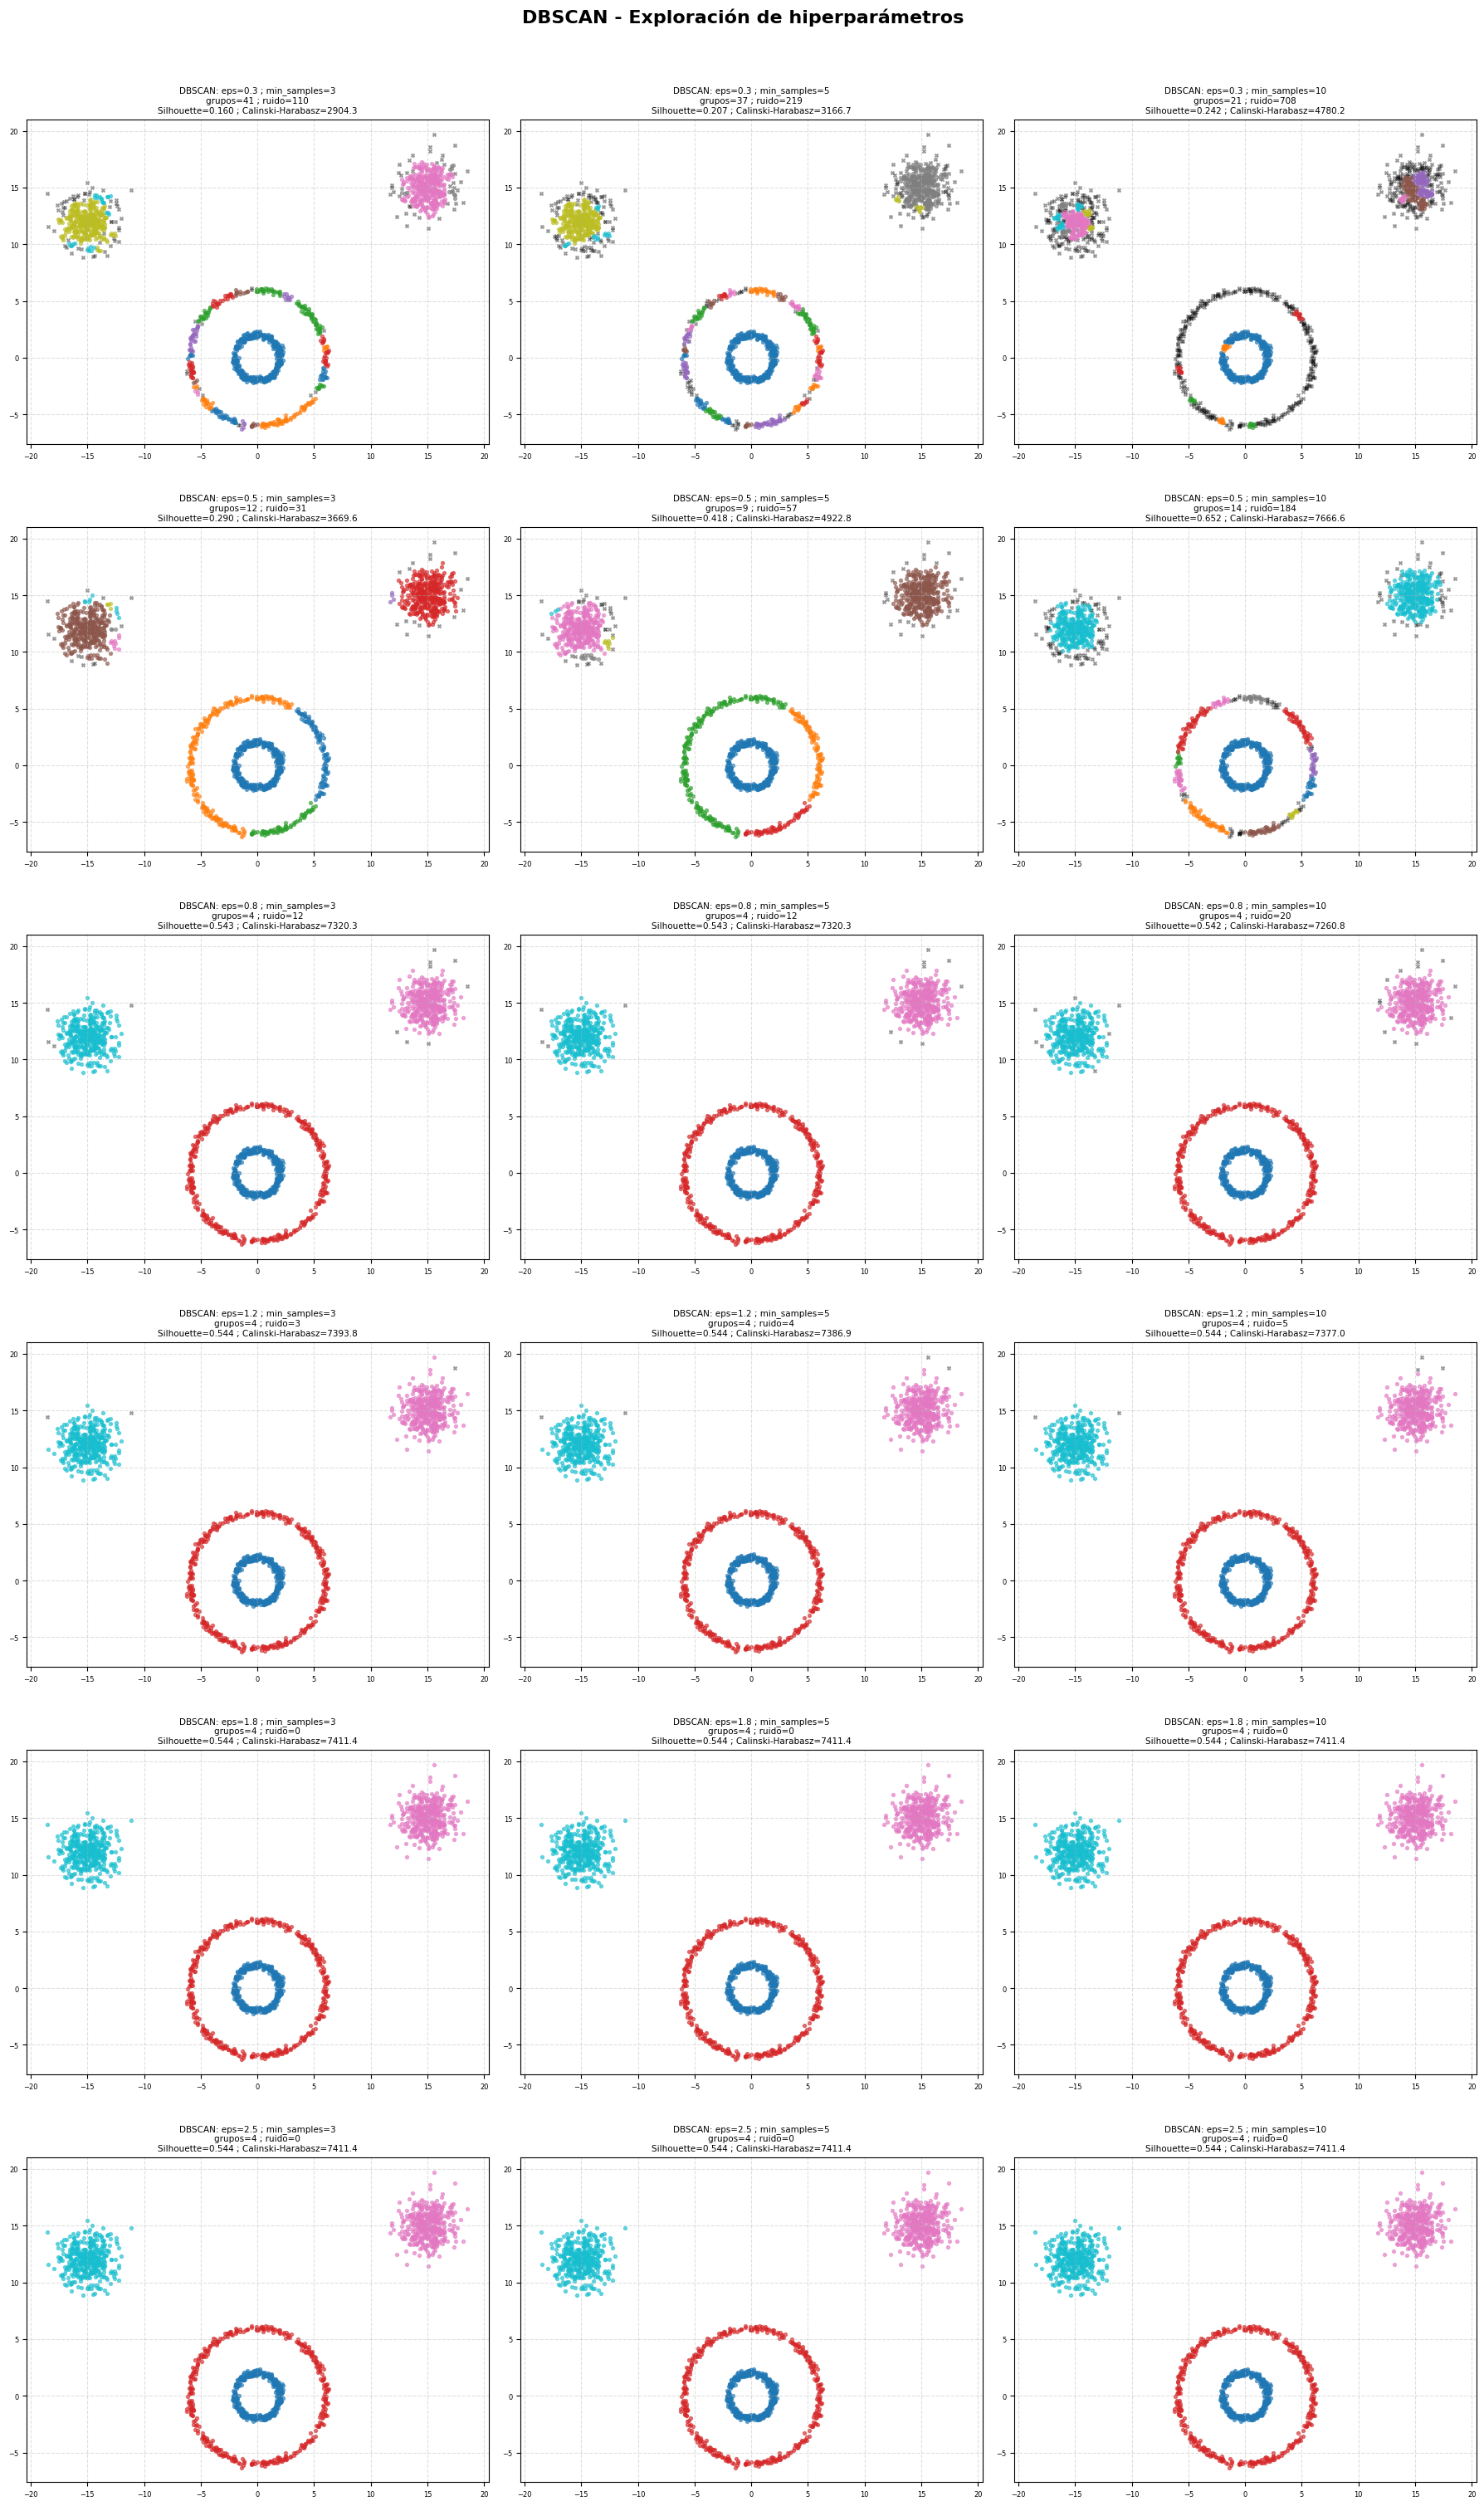

In [11]:
# ============================================================
# Tarea 2.1: Clustering con DBSCAN - cuadrícula 6x3
# ============================================================

# Valores de hiperparámetros a explorar
eps_values = [0.3, 0.5, 0.8, 1.2, 1.8, 2.5]
min_samples_values = [3, 5, 10]

# Array numpy del dataset
X_np = dataset.values

fig, axes = plt.subplots(6, 3, figsize=(18, 30))
fig.suptitle("DBSCAN - Exploración de hiperparámetros", fontsize=16, fontweight='bold', y=1.01)

for i, eps in enumerate(eps_values):
    for j, min_s in enumerate(min_samples_values):

        ax = axes[i][j]

        # Entrenamiento DBSCAN
        modelo = DBSCAN(eps=eps, min_samples=min_s)
        labels = modelo.fit_predict(X_np)

        # Número de grupos (sin contar ruido)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise    = int(np.sum(labels == -1))

        # Índices internos solo sobre puntos no ruido
        mask = labels != -1
        if n_clusters >= 2 and mask.sum() >= 2:
            sil = f"{silhouette_score(X_np[mask], labels[mask]):.3f}"
            ch  = f"{calinski_harabasz_score(X_np[mask], labels[mask]):.1f}"
        else:
            sil = "No definido"
            ch  = "No definido"

        # Colores: ruido en negro, grupos con paleta tab10
        colores = labels.copy().astype(object)
        palette = plt.cm.tab10(np.linspace(0, 1, max(n_clusters, 1)))
        unique_labels = sorted(set(labels))

        for lab in unique_labels:
            mask_lab = labels == lab
            if lab == -1:
                ax.scatter(X_np[mask_lab, 0], X_np[mask_lab, 1],
                           s=8, c='black', alpha=0.4, marker='x')
            else:
                color_idx = [l for l in unique_labels if l != -1].index(lab)
                ax.scatter(X_np[mask_lab, 0], X_np[mask_lab, 1],
                           s=8, alpha=0.6,
                           c=[plt.cm.tab10(color_idx / max(n_clusters - 1, 1))])

        ax.set_title(
            f"DBSCAN: eps={eps} ; min_samples={min_s}\n"
            f"grupos={n_clusters} ; ruido={n_noise}\n"
            f"Silhouette={sil} ; Calinski-Harabasz={ch}",
            fontsize=7.5
        )
        ax.set_aspect('equal')
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(labelsize=6)

plt.tight_layout()
plt.show()

## Análisis de resultados DBSCAN

### Rango de hiperparámetros óptimo

Los mejores resultados visuales se obtienen con valores de `eps` en el rango **[1.2, 1.8]**
combinados con cualquier valor de `min_samples` entre **3 y 10**. En este rango, DBSCAN
detecta correctamente las cuatro formas geométricas como grupos independientes: el anillo
exterior, el círculo interior, y las dos nubes de puntos compactas. El valor de `eps` es
suficientemente grande para conectar todos los puntos dentro de cada forma, y suficientemente
pequeño para no fusionar estructuras distintas que están separadas entre sí.

Con `eps` muy pequeño (por ejemplo, 0.3), el algoritmo fragmenta las formas en múltiples
microclústeres y genera muchos puntos de ruido, porque la vecindad es insuficiente para
enlazar puntos dentro de una misma estructura.

Con `eps` muy grande (por ejemplo, 2.5), las formas comienzan a fusionarse, reduciendo
el número de grupos detectados por debajo de cuatro.

El parámetro `min_samples` tiene muy poca influencia en este dataset con eps=1.8: los
valores 3, 5 y 10 producen exactamente el mismo resultado (4 grupos, 0 puntos de ruido),
lo que indica que la densidad de puntos en todas las formas es suficientemente alta para
superar cualquiera de estos umbrales.

### Relación con los índices internos

Los índices Silhouette y Calinski-Harabasz **no son buenos indicadores** para el resultado
que buscamos en este dataset. Ambos índices favorecen grupos compactos y convexos. En este
caso, la configuración óptima obtiene Silhouette=0.544 y Calinski-Harabasz=7411.4, valores
que no reflejan la excelente calidad visual del agrupamiento, ya que las formas detectadas
(anillos, círculos) son geométricamente irregulares. Es posible que configuraciones con
más grupos pero más compactos obtengan índices más altos sin ser visualmente mejores.

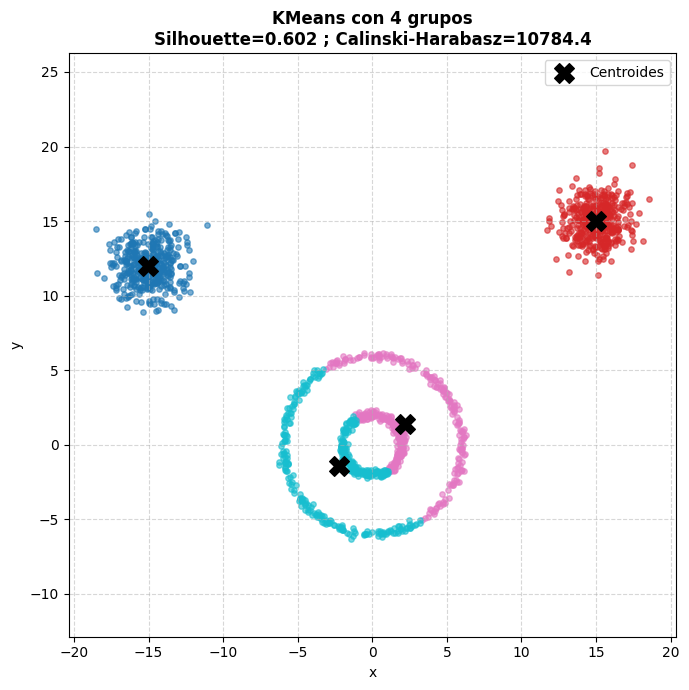

In [ ]:
# ============================================================
# Tarea 3.1: Clustering con KMeans - 4 grupos
# ============================================================

X_np = dataset.values

# Entrenamiento KMeans con 4 grupos
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km = kmeans.fit_predict(X_np)
centroides = kmeans.cluster_centers_

# Índices internos
sil_km = silhouette_score(X_np, labels_km)
ch_km  = calinski_harabasz_score(X_np, labels_km)

# Gráfico
plt.figure(figsize=(7, 7))

for lab in sorted(set(labels_km)):
    mask = labels_km == lab
    plt.scatter(X_np[mask, 0], X_np[mask, 1],
                s=15, alpha=0.6,
                c=[plt.cm.tab10(lab / 3)])

# Centroides
plt.scatter(centroides[:, 0], centroides[:, 1],
            s=200, c='black', marker='X', zorder=5, label='Centroides')

plt.title(
    f"KMeans con 4 grupos\n"
    f"Silhouette={sil_km:.3f} ; Calinski-Harabasz={ch_km:.1f}",
    fontweight='bold'
)
plt.xlabel(dataset.columns[0])
plt.ylabel(dataset.columns[1])
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Análisis de resultados KMeans

### ¿Consigue KMeans la agrupación buscada?

No. KMeans **no logra identificar correctamente las cuatro formas geométricas**. El algoritmo
asume que los grupos son convexos y de densidad similar, y minimiza la distancia euclídea al
centroide más cercano. Esto hace que divida las formas no convexas (como anillos o medias lunas)
en partes, asignando puntos de una misma forma geométrica a grupos distintos, y mezclando puntos
de formas diferentes en un mismo grupo.

### ¿Son buenos o malos los índices?

Los índices obtenidos con KMeans son **numéricamente superiores** a los obtenidos con la
configuración óptima de DBSCAN. Esto puede parecer contradictorio, pero se explica porque
Silhouette y Calinski-Harabasz miden compacidad y separación en el espacio euclídeo, y KMeans
genera grupos que, aunque geométricamente incorrectos, son más compactos y equidistantes entre
sí que los grupos irregulares que detecta DBSCAN.

En otras palabras, **unos índices altos no implican un buen agrupamiento visual**. Este es
precisamente uno de los grandes límites de los índices internos de validación: están sesgados
hacia geometrías convexas y no capturan la calidad estructural del agrupamiento cuando el dataset
presenta formas arbitrarias.

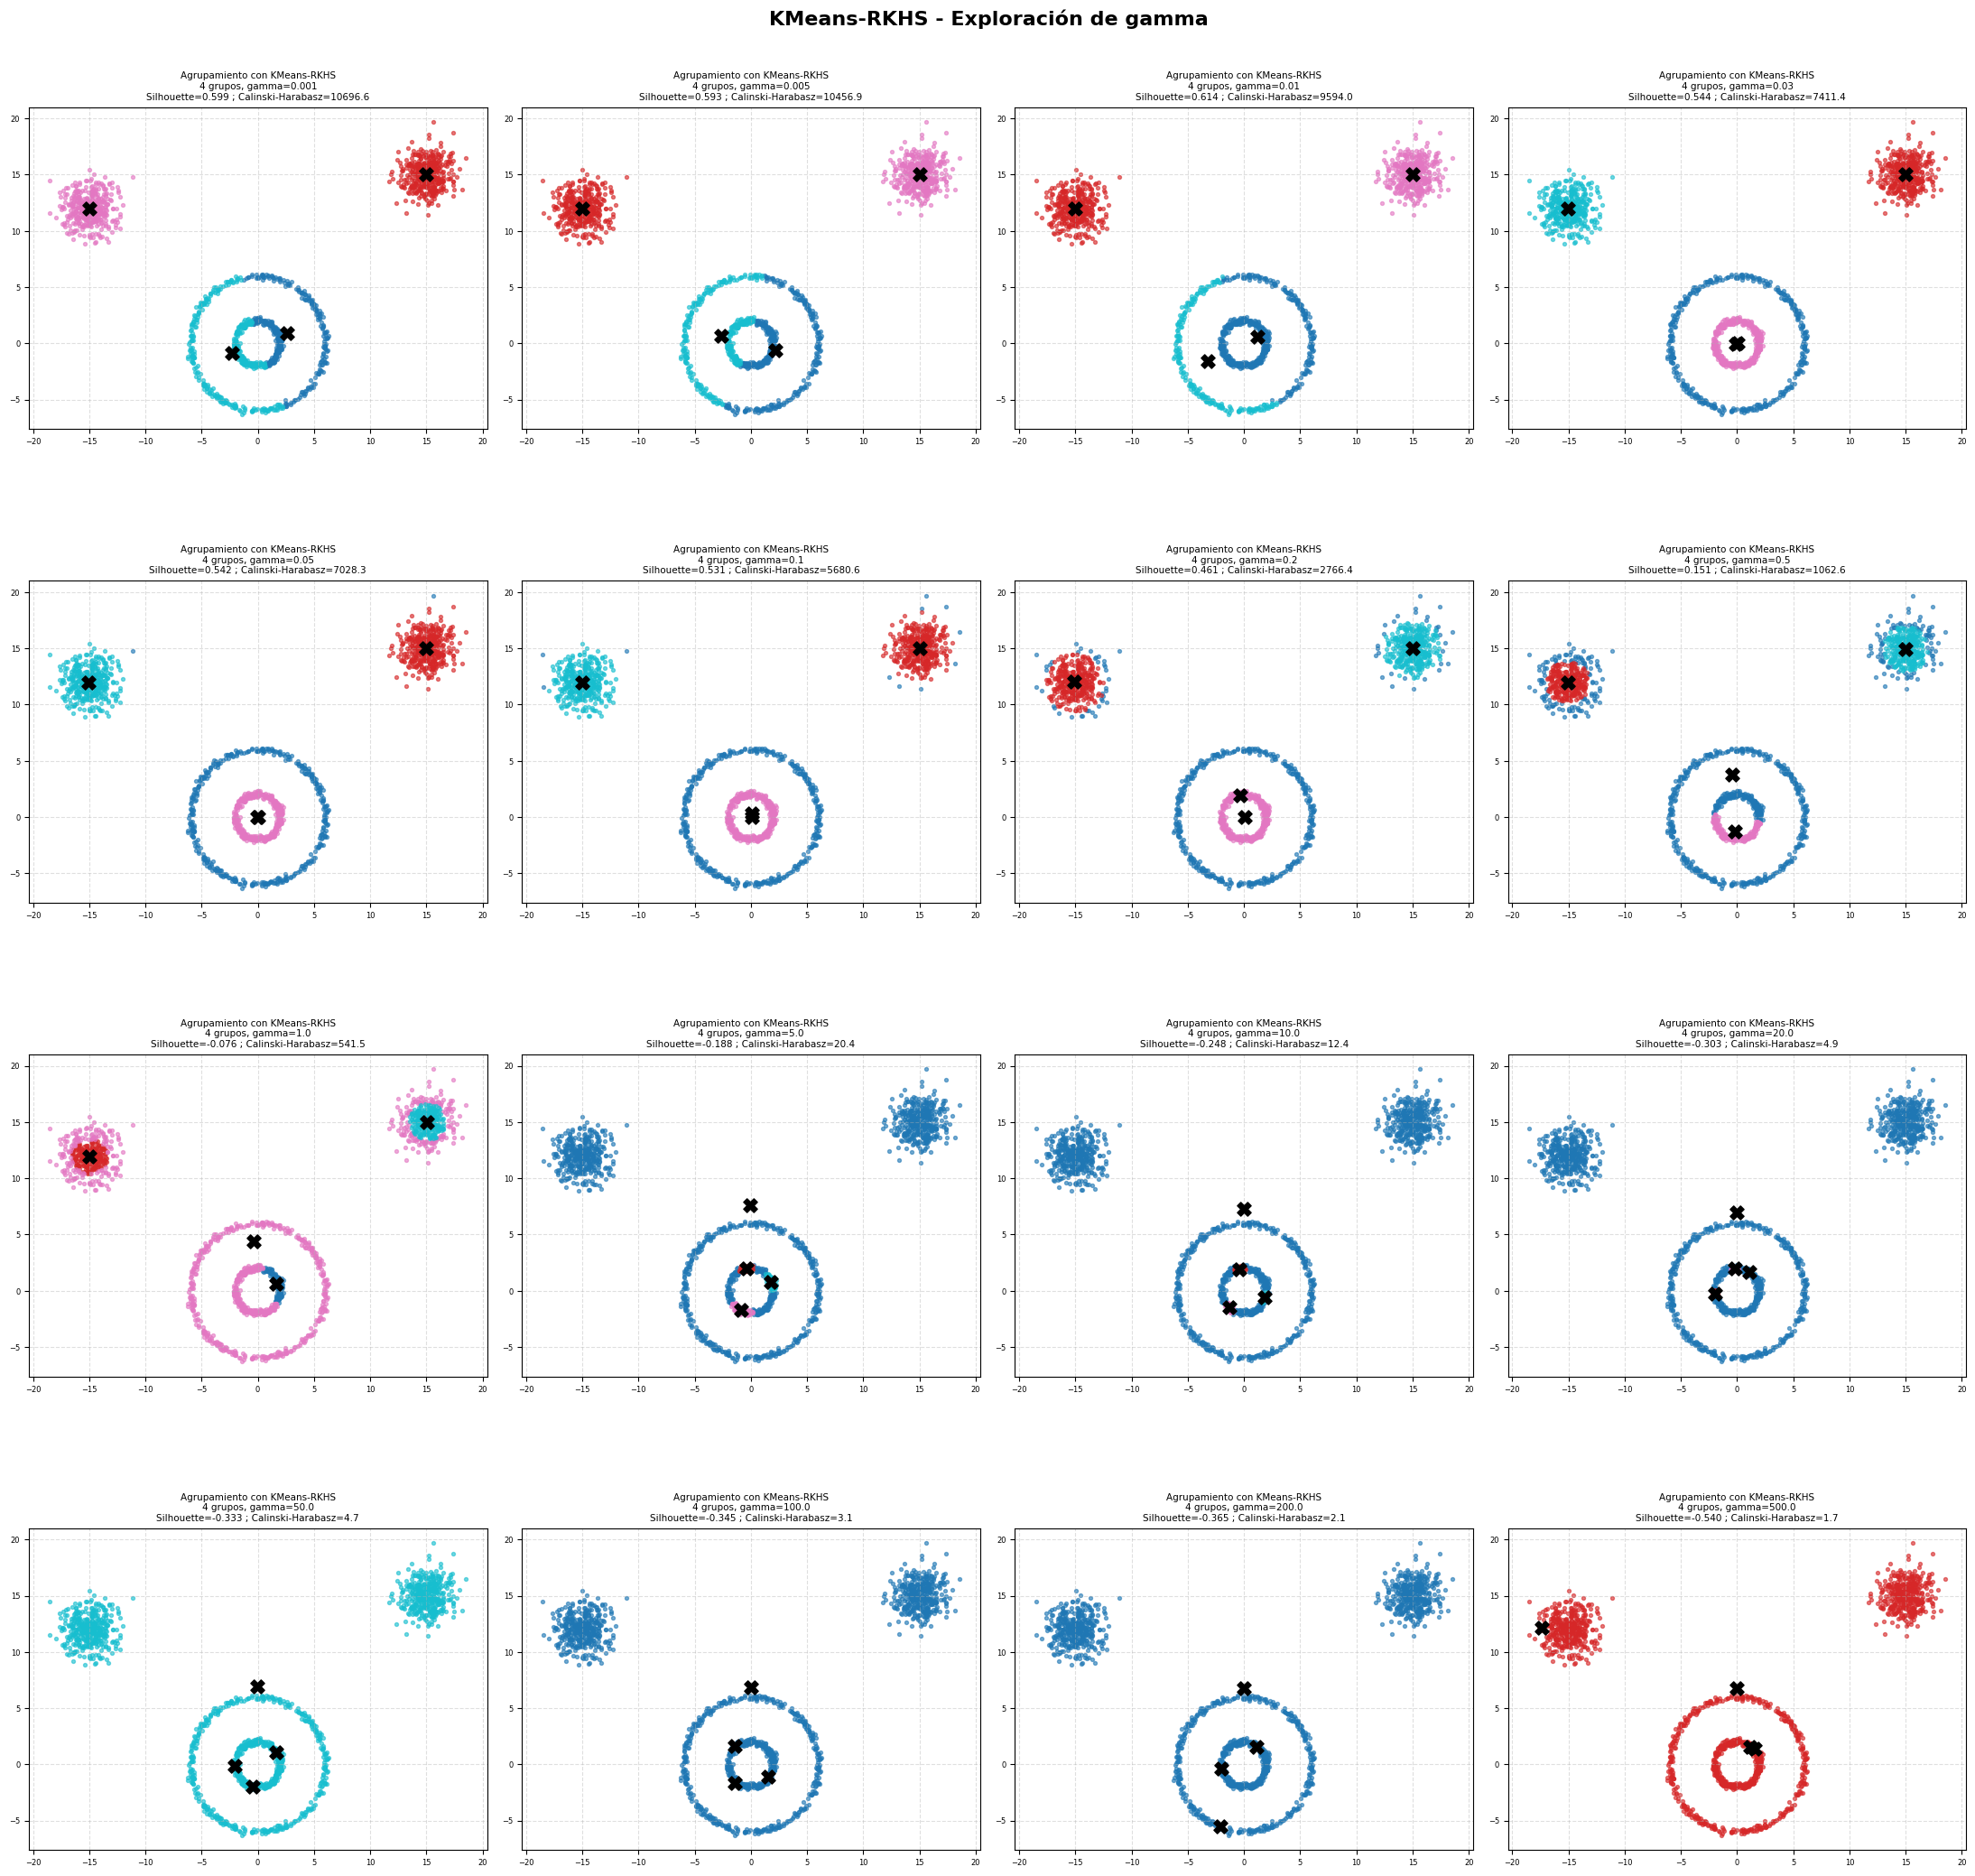

In [ ]:
# ============================================================
# Tarea 4.1: Clustering con KMeans-RKHS - cuadrícula 4x4
# ============================================================

from sklearn.metrics.pairwise import rbf_kernel

X_np = dataset.values

# 16 valores de gamma distribuidos en escala logarítmica
gamma_values = [0.001, 0.005, 0.01, 0.03, 0.05,
                0.1,   0.2,   0.5,  1.0,
                5.0,   10.0, 20.0,
                50.0,  100.0, 200.0, 500.0]

fig, axes = plt.subplots(4, 4, figsize=(22, 22))
fig.suptitle("KMeans-RKHS - Exploración de gamma", fontsize=16, fontweight='bold')

for idx, gamma in enumerate(gamma_values):
    ax = axes[idx // 4][idx % 4]

    # Construcción de la matriz kernel RBF
    K = rbf_kernel(X_np, gamma=gamma)

    # KMeans sobre el espacio RKHS (filas de K como nueva representación)
    kmeans_k = KMeans(n_clusters=4, random_state=42, n_init=10)
    labels_k = kmeans_k.fit_predict(K)
    centroides_k = kmeans_k.cluster_centers_

    # Índices internos (en el espacio original para comparación visual)
    sil_k = silhouette_score(X_np, labels_k)
    ch_k  = calinski_harabasz_score(X_np, labels_k)

    # Gráfico en espacio original, coloreado por etiqueta RKHS
    for lab in sorted(set(labels_k)):
        mask = labels_k == lab
        ax.scatter(X_np[mask, 0], X_np[mask, 1],
                   s=8, alpha=0.6,
                   c=[plt.cm.tab10(lab / 3)])

    # Centroides proyectados: centroide de cada grupo en espacio original
    for lab in sorted(set(labels_k)):
        mask = labels_k == lab
        cx = X_np[mask, 0].mean()
        cy = X_np[mask, 1].mean()
        ax.scatter(cx, cy, s=120, c='black', marker='X', zorder=5)

    ax.set_title(
        f"Agrupamiento con KMeans-RKHS\n"
        f"4 grupos, gamma={gamma}\n"
        f"Silhouette={sil_k:.3f} ; Calinski-Harabasz={ch_k:.1f}",
        fontsize=7.5
    )
    ax.set_aspect('equal')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.tick_params(labelsize=6)

plt.tight_layout()
plt.show()

## Análisis de resultados KMeans-RKHS

### Rango de gamma óptimo

KMeans-RKHS comienza a reconocer correctamente las cuatro formas geométricas para valores
de `gamma` en el rango **[0.03, 0.1]** aproximadamente. En este rango, el kernel RBF
transforma el espacio de características de forma que las estructuras no convexas (anillo
exterior, círculo interior) quedan separadas de las nubes de puntos compactas, permitiendo
que KMeans las identifique correctamente como grupos independientes.

Con `gamma` muy pequeño (por ejemplo, 0.001–0.01), la matriz kernel es casi constante y
la transformación apenas modifica la geometría del espacio. El resultado es prácticamente
idéntico al de KMeans estándar: los grupos son convexos y no respetan las formas reales
del dataset, mezclando puntos del anillo con puntos de las nubes.

Con `gamma` muy grande (por ejemplo, 1.0 en adelante), el kernel se vuelve muy local:
cada punto solo interactúa con sus vecinos más inmediatos, lo que fragmenta las estructuras
y produce grupos incorrectos o desequilibrados. A partir de gamma=5.0, prácticamente todos
los puntos quedan agrupados en un único color, perdiendo completamente la estructura buscada.

### Relación con los índices internos

En el rango óptimo de `gamma` [0.03, 0.1], los índices Silhouette y Calinski-Harabasz
**no son los más altos** de toda la exploración. Los valores más altos aparecen con gammas
pequeños (0.001–0.01), donde el resultado es visualmente incorrecto pero los grupos
generados son más compactos y esféricos en el espacio original.

Esto confirma que, al igual que con DBSCAN, los índices internos **no son buenos
indicadores** de la calidad visual del agrupamiento cuando el dataset contiene formas
no convexas. La selección del gamma óptimo debe hacerse visualmente, no guiándose
exclusivamente por estos índices.

In [12]:
# ============================================================
# Tarea 5.1: Entrenamiento final con hiperparámetros óptimos
# ============================================================

X_np = dataset.values

# --- DBSCAN óptimo (ajustar eps y min_samples según análisis visual de Tarea 2) ---
eps_opt        = 1.8
min_samples_opt = 3
dbscan_final = DBSCAN(eps=eps_opt, min_samples=min_samples_opt)
labels_dbscan = dbscan_final.fit_predict(X_np)

# --- KMeans óptimo ---
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_kmeans = kmeans_final.fit_predict(X_np)
centroides_km = kmeans_final.cluster_centers_

# --- KMeans-RKHS óptimo (ajustar gamma según análisis visual de Tarea 4) ---
gamma_opt = 0.03
K_opt = rbf_kernel(X_np, gamma=gamma_opt)
kmeansRKHS_final = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_rkhs = kmeansRKHS_final.fit_predict(K_opt)

# Centroides RKHS en espacio original (media de cada grupo)
centroides_rkhs = np.array([
    X_np[labels_rkhs == lab].mean(axis=0)
    for lab in sorted(set(labels_rkhs))
])

# Construcción del DataFrame agrupamientos
agrupamientos = dataset.copy()
agrupamientos['dbscan']      = labels_dbscan
agrupamientos['kmeans']      = labels_kmeans
agrupamientos['kmeansRKHS']  = labels_rkhs

print("Primeros elementos de agrupamientos:")
display(agrupamientos.head(10))

Primeros elementos de agrupamientos:


,x,y,dbscan,kmeans,kmeansRKHS
0,-1.214299,1.412649,0,3,2
1,1.908018,-0.443996,0,2,2
2,-0.123495,-1.970080,0,3,2
3,-1.674425,-1.139345,0,3,2
4,1.162182,1.606780,0,2,2
5,1.094287,1.652612,0,2,2
6,1.882833,0.759976,0,2,2
7,1.422948,-1.746932,0,2,2
8,-1.732492,-1.389105,0,3,2
9,-0.206944,-1.819511,0,3,2


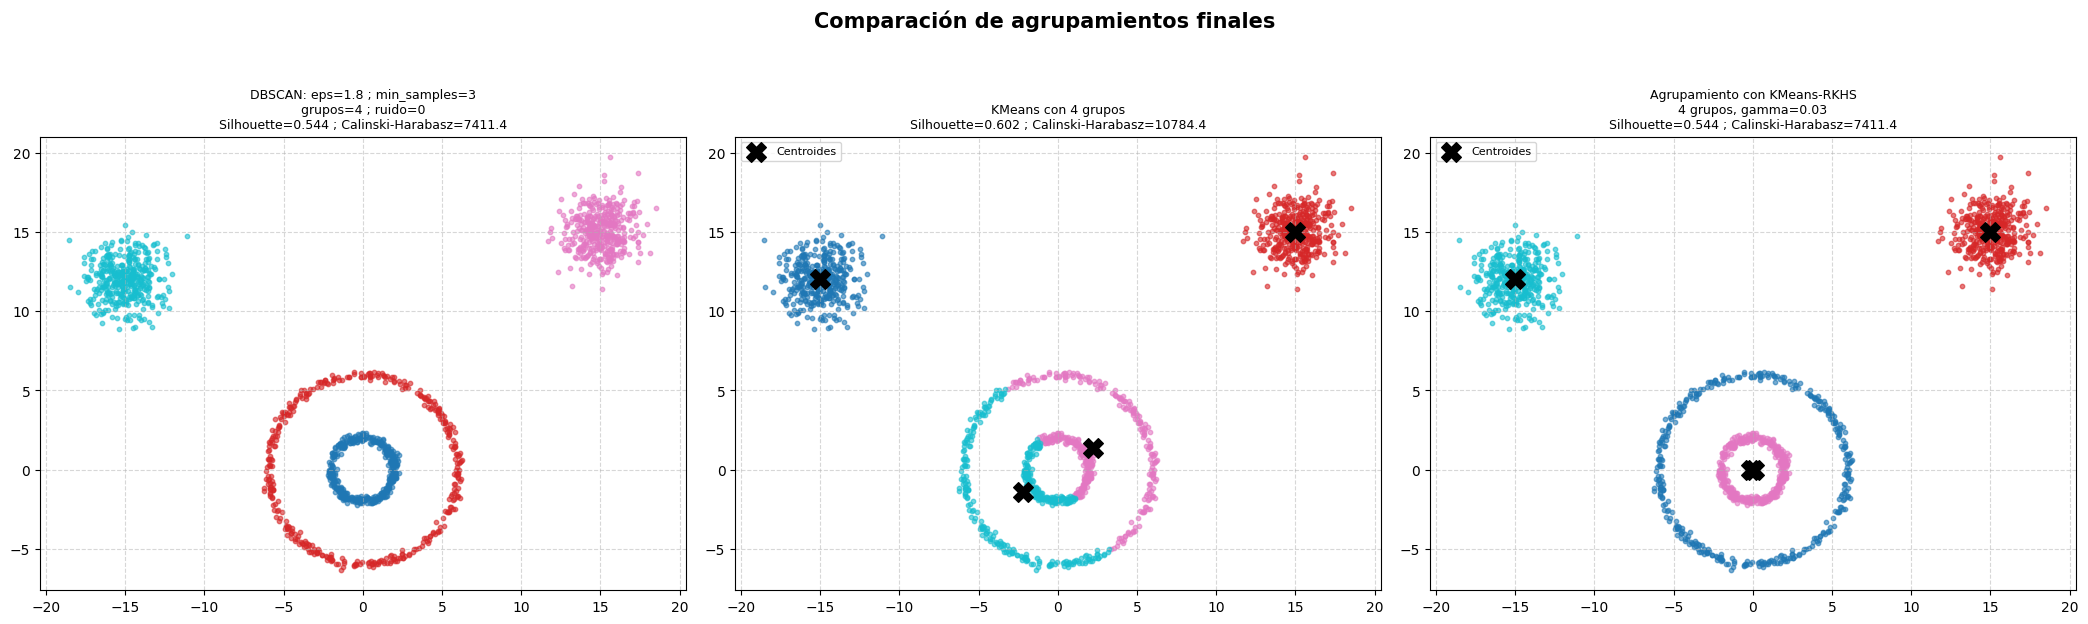

In [13]:
# ============================================================
# Tarea 5.2: Representación gráfica de los 3 agrupamientos
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
fig.suptitle("Comparación de agrupamientos finales", fontsize=15, fontweight='bold')

# ---------- DBSCAN ----------
ax = axes[0]
labels = agrupamientos['dbscan'].values
n_cl   = len(set(labels)) - (1 if -1 in labels else 0)
n_no   = int(np.sum(labels == -1))
mask   = labels != -1
sil_d  = f"{silhouette_score(X_np[mask], labels[mask]):.3f}" if n_cl >= 2 else "No definido"
ch_d   = f"{calinski_harabasz_score(X_np[mask], labels[mask]):.1f}" if n_cl >= 2 else "No definido"

for lab in sorted(set(labels)):
    m = labels == lab
    if lab == -1:
        ax.scatter(X_np[m, 0], X_np[m, 1], s=10, c='black', marker='x', alpha=0.4)
    else:
        ax.scatter(X_np[m, 0], X_np[m, 1], s=10, alpha=0.6,
                   c=[plt.cm.tab10(lab / max(n_cl - 1, 1))])

ax.set_title(f"DBSCAN: eps={eps_opt} ; min_samples={min_samples_opt}\n"
             f"grupos={n_cl} ; ruido={n_no}\n"
             f"Silhouette={sil_d} ; Calinski-Harabasz={ch_d}", fontsize=9)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)

# ---------- KMeans ----------
ax = axes[1]
labels = agrupamientos['kmeans'].values
sil_k  = silhouette_score(X_np, labels)
ch_k   = calinski_harabasz_score(X_np, labels)

for lab in sorted(set(labels)):
    m = labels == lab
    ax.scatter(X_np[m, 0], X_np[m, 1], s=10, alpha=0.6,
               c=[plt.cm.tab10(lab / 3)])

ax.scatter(centroides_km[:, 0], centroides_km[:, 1],
           s=200, c='black', marker='X', zorder=5, label='Centroides')
ax.set_title(f"KMeans con 4 grupos\n"
             f"Silhouette={sil_k:.3f} ; Calinski-Harabasz={ch_k:.1f}", fontsize=9)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=8)

# ---------- KMeans-RKHS ----------
ax = axes[2]
labels = agrupamientos['kmeansRKHS'].values
sil_r  = silhouette_score(X_np, labels)
ch_r   = calinski_harabasz_score(X_np, labels)

for lab in sorted(set(labels)):
    m = labels == lab
    ax.scatter(X_np[m, 0], X_np[m, 1], s=10, alpha=0.6,
               c=[plt.cm.tab10(lab / 3)])

ax.scatter(centroides_rkhs[:, 0], centroides_rkhs[:, 1],
           s=200, c='black', marker='X', zorder=5, label='Centroides')
ax.set_title(f"Agrupamiento con KMeans-RKHS\n"
             f"4 grupos, gamma={gamma_opt}\n"
             f"Silhouette={sil_r:.3f} ; Calinski-Harabasz={ch_r:.1f}", fontsize=9)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# Tarea 5.3: Validación externa entre algoritmos
# ============================================================

# Para validación externa, los puntos de ruido de DBSCAN se excluyen
# de todas las comparaciones que involucren DBSCAN
mask_no_ruido = agrupamientos['dbscan'] != -1

ldb  = agrupamientos.loc[mask_no_ruido, 'dbscan'].values
lkm  = agrupamientos.loc[mask_no_ruido, 'kmeans'].values
lrkh = agrupamientos.loc[mask_no_ruido, 'kmeansRKHS'].values

# Comparación completa KMeans vs KMeans-RKHS (sin excluir ruido)
lkm_all  = agrupamientos['kmeans'].values
lrkh_all = agrupamientos['kmeansRKHS'].values

def metricas(y1, y2):
    return {
        'ARI':            round(adjusted_rand_score(y1, y2), 4),
        'Homogeneidad':   round(homogeneity_score(y1, y2), 4),
        'Exhaustividad':  round(completeness_score(y1, y2), 4),
        'V-Score':        round(v_measure_score(y1, y2), 4),
        'NMI':            round(normalized_mutual_info_score(y1, y2), 4),
        'AMI':            round(adjusted_mutual_info_score(y1, y2), 4),
    }

filas = [
    {'Comparación': 'DBSCAN vs KMeans',       **metricas(ldb, lkm)},
    {'Comparación': 'DBSCAN vs KMeans-RKHS',  **metricas(ldb, lrkh)},
    {'Comparación': 'KMeans vs KMeans-RKHS',  **metricas(lkm_all, lrkh_all)},
]

validacion_ext = pd.DataFrame(filas).set_index('Comparación')

print("DataFrame validacion_ext:")
display(validacion_ext)

DataFrame validacion_ext:


,ARI,Homogeneidad,Exhaustividad,V-Score,NMI,AMI
Comparación,,,,,,
DBSCAN vs KMeans,0.6668,0.7504,0.7504,0.7504,0.7504,0.7499
DBSCAN vs KMeans-RKHS,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
KMeans vs KMeans-RKHS,0.6668,0.7504,0.7504,0.7504,0.7504,0.7499


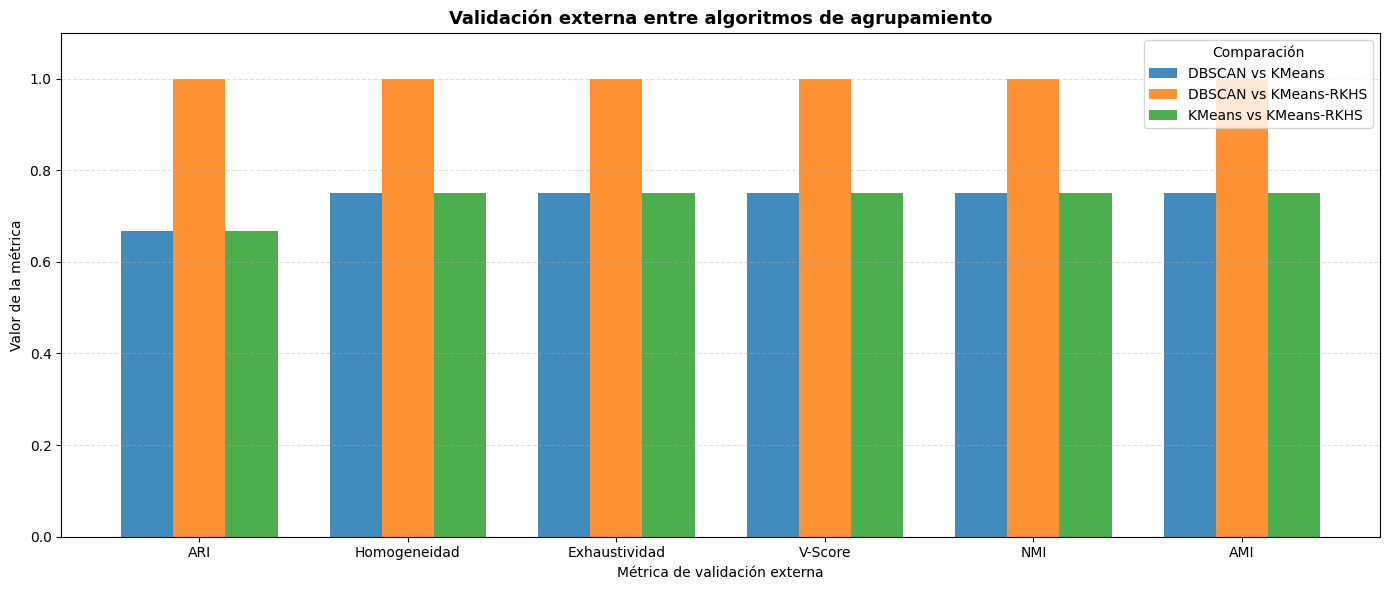

In [16]:
# ============================================================
# Tarea 5.4: Gráfico de barras agrupado - validación externa
# ============================================================

metricas_cols  = ['ARI', 'Homogeneidad', 'Exhaustividad', 'V-Score', 'NMI', 'AMI']
comparaciones  = validacion_ext.index.tolist()
colores        = ['#1f77b4', '#ff7f0e', '#2ca02c']  # azul, naranja, verde

x      = np.arange(len(metricas_cols))
ancho  = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

for i, (comp, color) in enumerate(zip(comparaciones, colores)):
    valores = validacion_ext.loc[comp, metricas_cols].values.astype(float)
    ax.bar(x + i * ancho, valores, ancho, label=comp, color=color, alpha=0.85)

ax.set_title("Validación externa entre algoritmos de agrupamiento",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Métrica de validación externa")
ax.set_ylabel("Valor de la métrica")
ax.set_xticks(x + ancho)
ax.set_xticklabels(metricas_cols)
ax.set_ylim(0, 1.1)
ax.legend(title="Comparación")
ax.grid(True, linestyle='--', alpha=0.4, axis='y')

plt.tight_layout()
plt.show()

## Análisis de la validación externa

La validación externa compara los agrupamientos de dos en dos, evaluando en qué medida
dos algoritmos han asignado los mismos puntos a los mismos grupos, independientemente del
nombre de la etiqueta.

### DBSCAN vs KMeans

Esta comparación obtiene valores intermedios en todas las métricas: ARI=0.6668,
Homogeneidad=0.7504, Exhaustividad=0.7504, V-Score=0.7504, NMI=0.7504 y AMI=0.7499.
Estos valores indican que ambos algoritmos coinciden parcialmente, pero han llegado a
soluciones distintas. DBSCAN detecta correctamente las formas geométricas reales, mientras
que KMeans genera grupos convexos que no respetan esas estructuras. El ARI de 0.6668,
ajustado por azar, confirma que el acuerdo entre ambos algoritmos es real pero imperfecto.

### DBSCAN vs KMeans-RKHS

Esta comparación obtiene valores perfectos en todas las métricas: ARI=1.0,
Homogeneidad=1.0, Exhaustividad=1.0, V-Score=1.0, NMI=1.0 y AMI=1.0. Esto significa
que DBSCAN y KMeans-RKHS han asignado exactamente los mismos puntos a los mismos grupos,
con total coincidencia. Ambos algoritmos han llegado a la misma solución por caminos
distintos: DBSCAN mediante densidad local, y KMeans-RKHS mediante la transformación
kernel del espacio de características.

### KMeans vs KMeans-RKHS

Esta comparación obtiene los mismos valores que DBSCAN vs KMeans: ARI=0.6668,
Homogeneidad=0.7504, Exhaustividad=0.7504, V-Score=0.7504, NMI=0.7504 y AMI=0.7499.
Aunque KMeans-RKHS parte del mismo algoritmo base que KMeans, la transformación kernel
RBF cambia fundamentalmente la geometría del espacio de trabajo, llevando a una solución
completamente diferente. KMeans-RKHS coincide perfectamente con DBSCAN pero solo
parcialmente con KMeans estándar, lo que demuestra el impacto real del kernel.

### Conclusión general

Los resultados de la validación externa son completamente coherentes con el análisis
visual: DBSCAN y KMeans-RKHS producen exactamente el mismo agrupamiento (coincidencia
perfecta de 1.0), mientras que KMeans estándar llega a una solución estructuralmente
diferente. Las métricas ARI y AMI, al estar ajustadas por azar, son las más fiables
e informativas de esta comparación.